# BCMO Gap Analysis — Example (§3b)

Reproduces **§3b of `paper/ontology_gap_analysis.md`**: gap filling on 12 realistic patient statements (BCMO v2.1 → v2.2).

Each statement is evaluated two ways:
1. **Gold triples** (`data/examples/patient_claims_gold.json`): isolates the **ontology**.
2. **Raw text through the rule-based `ClaimExtractor`** (`data/examples/patient_statements.txt`): tests the **end-to-end pipeline**.

All outputs (gap log and the new ontology version) are written to a temporary folder, so the committed `data/bcmo_v2.2.json` is not modified.

In [1]:
import sys, json, tempfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import ontology.gap_filler as g
from ontology.bcmo_queries import BCMO
from pipeline.entity_linker import EntityLinker

DATA = ROOT / 'data'
OUT = Path(tempfile.mkdtemp(prefix='bcmo_gap_'))
g.DATA_DIR = OUT                         # merged ontology versions go here
g.GAPS_PATH = OUT / 'example_gaps.json'  # gap log goes here
BASE = DATA / 'bcmo_v2.1.json'
pd.set_option('display.max_colwidth', 90)
print('outputs ->', OUT)

outputs -> /var/folders/fw/jjvv22050k19sr97kh_2y3br0000gn/T/bcmo_gap_kfahephn


## 1. Inputs: patient statements and gold annotations

`truth` is the ground-truth label for each statement.

In [2]:
gold = g.load_claims(DATA / 'examples' / 'patient_claims_gold.json')
TRUTH = ['myth','true','myth','true','true','true','myth','true','true','myth','true','misleading']
pd.DataFrame([{'statement': c.source_text, 'subject': c.subject, 'relation': c.relation,
               'object': c.object, 'negated': c.negated, 'truth': t} for c, t in zip(gold, TRUTH)])

,statement,subject,relation,object,negated,truth
0,My aunt says drinking alcohol has nothing to do with breast cancer.,alcohol,increases_risk_of,breast cancer,True,myth
1,I read that tamoxifen causes hot flashes.,tamoxifen,has_side_effect,hot flashes,False,true
2,"Deodorant causes breast cancer, so I stopped using it.",deodorant,causes,breast cancer,False,myth
3,Breastfeeding reduces the risk of breast cancer.,breastfeeding,decreases_risk_of,breast cancer,False,true
4,My doctor said chemotherapy causes hair loss.,chemotherapy,has_side_effect,hair loss,False,true
5,Mammograms can detect breast cancer early.,mammograms,detects,breast cancer,False,true
6,Turmeric cures breast cancer better than chemo.,turmeric,treats,breast cancer,False,myth
7,Being overweight increases the risk of breast cancer.,overweight,increases_risk_of,breast cancer,False,true
8,Herceptin treats HER2-positive breast cancer.,herceptin,treats,HER2-positive breast cancer,False,true
9,Abortion increases the risk of breast cancer.,abortion,increases_risk_of,breast cancer,False,myth


## 2. Verdict function

`verify_claim` does not yet apply the claim's negation flag, so the flip is done here. A supported triple combined with `negated=True` gives *contradicted* (see the note in §3b).

In [3]:
def verdict(claim, bcmo, linker):
    s, o = linker.link(claim.subject), linker.link(claim.object)
    if 'unlinked' in (s.match_type, o.match_type):
        return 'unsupported (unlinked)'
    v, _ = bcmo.verify_claim(s.canonical_name, claim.relation, o.canonical_name)
    if claim.negated and v in ('supported', 'contradicted'):
        v = 'contradicted' if v == 'supported' else 'supported'
    return v

def evaluate(claims, bcmo):
    L = EntityLinker(bcmo)
    return [verdict(c, bcmo, L) for c in claims]

v21 = BCMO(BASE)
before = evaluate(gold, v21)

## 3. Detect gaps and propose fixes (with evidence)

In [4]:
if g.GAPS_PATH.exists(): g.GAPS_PATH.unlink()
g.detect_gaps(gold, v21)
store = g.propose(bcmo=v21)

def gap_table(store):
    rows = []
    for x in store['gaps'].values():
        detail = (f"({x['subject']}, {x['relation']}, {x['object']})" if x['type'] == 'relation'
                  else x['entity'])
        ev = (x.get('evidence') or [{}])[0]
        rows.append({'id': x['id'], 'type': x['type'], 'status': x['status'],
                     'evidence_label': x.get('evidence_label'), 'detail': detail,
                     'proposed_class': (x.get('proposal') or {}).get('class'),
                     'evidence': ev.get('sentence')})
    return pd.DataFrame(rows).sort_values(['type', 'status'])

gap_table(store)

,id,type,status,evidence_label,detail,proposed_class,evidence
0,con-8289b549,concept,proposed,known_misinformation,deodorant,MisinformationTopic,None
2,con-c4289e7b,concept,proposed,unverifiable,turmeric,NaN,None
4,con-4808d65f,concept,proposed,unverifiable,abortion,NaN,None
6,con-ada15bd1,concept,proposed,known_misinformation,sugar,MisinformationTopic,None
1,rel-a2520e41,relation,open,blocked_by_entity_gap,"(deodorant, causes, Breast Cancer)",NaN,None
3,rel-2af56689,relation,open,blocked_by_entity_gap,"(turmeric, treats, Breast Cancer)",NaN,None
5,rel-57bc0eaf,relation,open,blocked_by_entity_gap,"(abortion, increases_risk_of, Breast Cancer)",NaN,None
7,rel-e070f1aa,relation,open,blocked_by_entity_gap,"(sugar, causes, Breast Cancer)",NaN,None


## 4. Review and merge into v2.2

Auto-approves only proposals backed by evidence (lexical, MedQuAD, or the curated myth list). A second pass then re-checks relations that were blocked by a missing entity.

In [5]:
g.review(approve_evidenced=True)
g.merge('2.2', base=BASE)

store = g.load_gaps()
v22 = BCMO(OUT / 'bcmo_v2.2.json')
g.propose(store, v22); g.review(approve_evidenced=True, store=store)
g.merge('2.2', base=OUT / 'bcmo_v2.2.json', store=store)

v22 = BCMO(OUT / 'bcmo_v2.2.json')
print(v22.data['ontology_metadata']['gap_filler_additions'])
gap_table(g.load_gaps())

Wrote bcmo_gap_kfahephn/bcmo_v2.2.json: {'add_alias': 0, 'add_concept': 2, 'add_relation': 0}
Wrote bcmo_gap_kfahephn/bcmo_v2.2.json: {'add_alias': 0, 'add_concept': 0, 'add_relation': 1}
{'add_alias': 0, 'add_concept': 2, 'add_relation': 1}


,id,type,status,evidence_label,detail,proposed_class,evidence
0,con-8289b549,concept,merged,known_misinformation,deodorant,MisinformationTopic,NaN
6,con-ada15bd1,concept,merged,known_misinformation,sugar,MisinformationTopic,NaN
2,con-c4289e7b,concept,proposed,unverifiable,turmeric,NaN,NaN
4,con-4808d65f,concept,proposed,unverifiable,abortion,NaN,NaN
1,rel-a2520e41,relation,merged,contradicted,"(Deodorant, causes, Breast Cancer)",NaN,No conclusive evidence links deodorant use to breast cancer
3,rel-2af56689,relation,open,blocked_by_entity_gap,"(turmeric, treats, Breast Cancer)",NaN,NaN
5,rel-57bc0eaf,relation,open,blocked_by_entity_gap,"(abortion, increases_risk_of, Breast Cancer)",NaN,NaN
7,rel-e070f1aa,relation,proposed,unverifiable,"(Sugar, causes, Breast Cancer)",NaN,NaN


## 5. Per-claim results: v2.1 vs v2.2 (gold triples)

In [6]:
after = evaluate(gold, v22)

def correct(v, truth):
    if truth == 'true':  return v == 'supported'
    if truth == 'myth':  return v == 'contradicted'
    return v == 'misleading'

res = pd.DataFrame({'statement': [c.source_text for c in gold], 'truth': TRUTH,
                    'v2.1': before, 'v2.2': after})
res['changed'] = res['v2.1'] != res['v2.2']
res['correct_v2.2'] = [correct(v, t) for v, t in zip(after, TRUTH)]
res['wrong_v2.2'] = [(not v.startswith('unsupported')) and not correct(v, t) for v, t in zip(after, TRUTH)]
res.style.apply(lambda r: ['background-color:#e6f4ea' if r['changed'] else '' for _ in r], axis=1)

,statement,truth,v2.1,v2.2,changed,correct_v2.2,wrong_v2.2
0,My aunt says drinking alcohol has nothing to do with breast cancer.,myth,contradicted,contradicted,False,True,False
1,I read that tamoxifen causes hot flashes.,true,supported,supported,False,True,False
2,"Deodorant causes breast cancer, so I stopped using it.",myth,unsupported (unlinked),contradicted,True,True,False
3,Breastfeeding reduces the risk of breast cancer.,true,supported,supported,False,True,False
4,My doctor said chemotherapy causes hair loss.,true,supported,supported,False,True,False
5,Mammograms can detect breast cancer early.,true,supported,supported,False,True,False
6,Turmeric cures breast cancer better than chemo.,myth,unsupported (unlinked),unsupported (unlinked),False,False,False
7,Being overweight increases the risk of breast cancer.,true,supported,supported,False,True,False
8,Herceptin treats HER2-positive breast cancer.,true,supported,supported,False,True,False
9,Abortion increases the risk of breast cancer.,myth,unsupported (unlinked),unsupported (unlinked),False,False,False


## 6. Coverage summary

In [7]:
def summary(verdicts, bcmo):
    L = EntityLinker(bcmo)
    ents = [e for c in gold for e in (c.subject, c.object)]
    myths = [i for i, t in enumerate(TRUTH) if t != 'true']
    return {
        'entities linked': f"{sum(L.link(e).match_type != 'unlinked' for e in ents)}/{len(ents)}",
        'claims with verdict': f"{sum(not v.startswith('unsupported') for v in verdicts)}/{len(verdicts)}",
        'misinformation recall': f"{sum(correct(verdicts[i], TRUTH[i]) for i in myths)}/{len(myths)}",
        'wrong verdicts': sum((not v.startswith('unsupported')) and not correct(v, t)
                              for v, t in zip(verdicts, TRUTH)),
    }

cov = pd.DataFrame({'v2.1': summary(before, v21), 'v2.2': summary(after, v22)})
cov

,v2.1,v2.2
entities linked,20/24,22/24
claims with verdict,8/12,9/12
misinformation recall,1/5,2/5
wrong verdicts,0,0


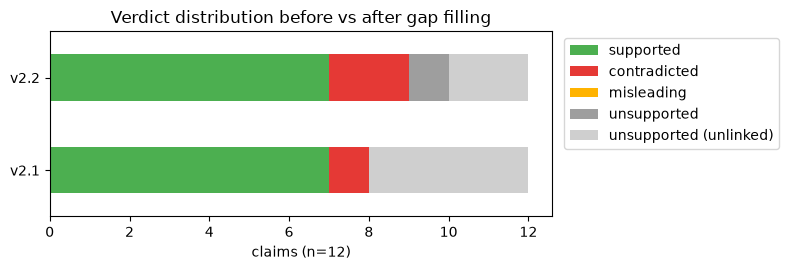

In [8]:
order = ['supported', 'contradicted', 'misleading', 'unsupported', 'unsupported (unlinked)']
counts = pd.DataFrame({'v2.1': pd.Series(before).value_counts(),
                       'v2.2': pd.Series(after).value_counts()}).reindex(order).fillna(0).dropna(how='all')
ax = counts.T.plot(kind='barh', stacked=True, figsize=(8, 2.8),
                   color=['#4caf50', '#e53935', '#ffb300', '#9e9e9e', '#cfcfcf'])
ax.set_xlabel('claims (n=12)'); ax.set_title('Verdict distribution before vs after gap filling')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left'); plt.tight_layout(); plt.show()

## 7. Remaining gaps: why each myth still fails

Each unresolved myth fails for a different reason, and each one points to a specific fix.

In [9]:
reasons = {
    'turmeric': 'Missing is_a link (Turmeric → Natural Remedy), so the "natural remedies cure" myth is never reached',
    'abortion': 'True coverage gap: the myth is absent from BCMO and MedQuAD and needs an ACS/NCI source',
    'sugar':    'Concept was added, but its myth entry has verdict "misleading", and only "false" myths become contradictions',
}
pd.DataFrame([{'statement': c.source_text, 'v2.2': a, 'reason': reasons.get(c.subject.lower())}
              for c, a, t in zip(gold, after, TRUTH) if t != 'true' and not correct(a, t)])

,statement,v2.2,reason
0,Turmeric cures breast cancer better than chemo.,unsupported (unlinked),"Missing is_a link (Turmeric → Natural Remedy), so the ""natural remedies cure"" myth is ..."
1,Abortion increases the risk of breast cancer.,unsupported (unlinked),True coverage gap: the myth is absent from BCMO and MedQuAD and needs an ACS/NCI source
2,Sugar feeds cancer cells and causes breast cancer.,unsupported,"Concept was added, but its myth entry has verdict ""misleading"", and only ""false"" myths..."


## 8. End-to-end: raw text through the rule-based ClaimExtractor

The same sentences are now fed through the claim extractor to see where errors happen *before* the ontology is reached.

In [10]:
from pipeline.claim_extractor import ClaimExtractor
ext = ClaimExtractor()
L22 = EntityLinker(v22)
rows = []
for sent, gc, t in zip((DATA / 'examples' / 'patient_statements.txt').read_text().splitlines(), gold, TRUTH):
    claims = ext.extract(sent)
    if not claims:
        rows.append({'statement': sent, 'truth': t, 'extracted': '— none —', 'verdict': 'no claim', 'issue': 'extraction miss'})
        continue
    for c in claims:
        v = verdict(c, v22, L22)
        issue = ''
        if t == 'myth' and v == 'supported':
            issue = 'MYTH LABELLED SUPPORTED (extraction error)'
        rows.append({'statement': sent, 'truth': t, 'extracted': repr(c), 'verdict': v, 'issue': issue})
e2e = pd.DataFrame(rows)
e2e.style.apply(lambda r: ['background-color:#fdecea' if r['issue'].startswith('MYTH') else
                           ('background-color:#fff8e1' if r['issue'] else '') for _ in r], axis=1)

,statement,truth,extracted,verdict,issue
0,My aunt says drinking alcohol has nothing to do with breast cancer.,myth,"(breast cancer, associated_with, alcohol)",unsupported,
1,I read that tamoxifen causes hot flashes.,true,"(tamoxifen, has_side_effect, hot flashes)",supported,
2,"Deodorant causes breast cancer, so I stopped using it.",myth,— none —,no claim,extraction miss
3,Breastfeeding reduces the risk of breast cancer.,true,"(breastfeeding, decreases_risk_of, breast cancer)",supported,
4,My doctor said chemotherapy causes hair loss.,true,"(chemotherapy, has_side_effect, hair loss)",supported,
5,Mammograms can detect breast cancer early.,true,— none —,no claim,extraction miss
6,Turmeric cures breast cancer better than chemo.,myth,"(chemo, treats, breast cancer)",supported,MYTH LABELLED SUPPORTED (extraction error)
7,Being overweight increases the risk of breast cancer.,true,— none —,no claim,extraction miss
8,Herceptin treats HER2-positive breast cancer.,true,"(herceptin, treats, HER2-positive breast cancer)",supported,
9,Herceptin treats HER2-positive breast cancer.,true,"(herceptin, treats, breast cancer)",supported,


In [11]:
print('sentences with no extracted claim:', (e2e['verdict'] == 'no claim').sum(), '/ 12')
print('myths labelled supported because of extraction:', e2e['issue'].str.startswith('MYTH').sum())

sentences with no extracted claim: 5 / 12
myths labelled supported because of extraction: 1


## 9. Takeaways

1. **When the ontology answers, it is right.** There were 0 wrong verdicts on gold triples. The remaining problem is coverage: the ontology is precise but incomplete.
2. **Gap filling helped in a measurable way.** The deodorant myth went from *unsupported* to *contradicted*, with an NCI source.
3. **Myth coverage is the weak spot.** The three remaining failures each have a concrete fix: add an `is_a` link, add an expert-sourced myth, and map `misleading` myth entries to the `misleading` verdict.
4. **End to end, the claim extractor is the bottleneck.** Every wrong label in the pipeline came from extraction, not the ontology. The study has to attribute errors separately for each part.